# 07 · Data Split — grouped and stratified 70 / 15 / 15

**In short:** the cleaned training images (PlantVillage, FieldPlant, Tanzania potato) are
divided into **train** (to learn from), **val** (to tune and calibrate) and **test** (to
report the final score). PlantDoc is never split; it stays the out-of-domain test.

**Why groups?** Photos of the same leaf or plant look almost identical. If one went to
train and its twin to test, the model would be tested on something it had already seen,
and the score would look better than it really is. So related photos are tied into a
**group**, and a whole group always goes to the same partition. Photos are tied together
when they share:

- a **PlantVillage leaf record** (4 photos per leaf; maize has no records),
- a **FieldPlant source photo** (several leaves cropped from one picture),
- a **Tanzania capture session** (photos taken minutes apart, same class),
- a **near-duplicate group** from cleaning.

**How the split is made:** the groups are dealt into 20 equal folds that each keep the same
mix of source and class (`StratifiedGroupKFold`, seed 42); 14 folds become train, 3 val, 3 test.

The notebook **stops after the Tanzania time-gap tables** so the session cut-off can be
chosen from the numbers. Runs on a CPU runtime.

In [1]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount("/content/drive")

REPO_URL = "https://github.com/BilliartMuthoni/confidence-calibrated-crop-diagnosis.git"
REPO_DIR = Path("/content/drive/MyDrive/Sproutly-app")

if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}

ML_DIR = REPO_DIR / "ml"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config

Mounted at /content/drive


In [2]:
# Keep the Drive copy of the repository in sync with GitHub.
!git -C {REPO_DIR} config core.fileMode false
!git -C {REPO_DIR} pull --ff-only
!git -C {REPO_DIR} status --short --branch

Already up to date.
Refresh index: 100% (92/92), done.
## main...origin/main
 M ml/notebooks/07_data_split.ipynb


In [3]:
%pip install -q -r {ML_DIR}/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 77.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.4 MB/s eta 0:00:00


## Load the cleaned images

Only images kept by cleaning (`keep == True`) are used.

In [4]:
import pandas as pd

from src.data import split

manifest = pd.read_csv(config.METADATA_DIR / "clean_manifest.csv")
kept = manifest[manifest["keep"]]
pool = kept[kept["subset"] == "train_pool"].copy()
ood_test = kept[kept["subset"] == "ood_in_scope"].copy()
unseen_test = kept[kept["subset"] == "ood_unseen"].copy()

print("Training pool:", len(pool), pool["source"].value_counts().to_dict())
print("PlantDoc in scope:", len(ood_test), "| PlantDoc unseen:", len(unseen_test))

Training pool: 16303 {'plantvillage': 12617, 'tanzania': 2797, 'fieldplant': 889}
PlantDoc in scope: 953 | PlantDoc unseen: 371


## Tanzania: look at the time gaps

A **session** is a run of photos taken close together in time; a new session starts when
the gap to the previous photo is longer than a cut-off. Sessions are found on **all 58,709
photos**, not the 3,000-photo sample: the sample keeps about 1 photo in 20, so gaps between
sampled photos look about 20 times longer than they really are.

The first table shows typical gaps (in minutes) between consecutive photos. The second shows,
for each candidate cut-off, how many sessions there are and how large the biggest one is
**within the sample**. A session holding more than a few percent of a class's sample is hard
to fit into a 15% partition.

In [5]:
inventory = pd.read_csv(config.METADATA_DIR / "tanzania_inventory.csv", parse_dates=["capture_time"])
tz_pool = pool[pool["source"] == "tanzania"].assign(file=lambda d: d["path"].str.rsplit("/", n=1).str[-1])

print("Photos without a capture time:", inventory["capture_time"].isna().sum(), "(each becomes its own session)")
print("\nMinutes between consecutive photos:")
display(split.gap_quantiles(inventory))

CANDIDATE_CUTOFFS = [2, 5, 10, 30]
display(split.gap_table(inventory, tz_pool, CANDIDATE_CUTOFFS))

Photos without a capture time: 7 (each becomes its own session)

Minutes between consecutive photos:


,p50,p75,p90,p95,p99
Potato___Early_blight,0.00,0.00,0.02,0.05,0.48
Potato___Late_blight,0.00,0.03,0.12,0.22,0.90
Potato___healthy,0.02,0.08,0.15,0.27,2.57


,cutoff_min,class,sessions,median_size,largest_size,largest_in_sample,largest_share_of_sample
0,2,Potato___Early_blight,81,7,8486,381,0.457
1,2,Potato___Late_blight,107,11,2682,112,0.115
2,2,Potato___healthy,248,36,1802,94,0.095
3,5,Potato___Early_blight,41,4,11270,540,0.648
4,5,Potato___Late_blight,68,8,6392,309,0.319
5,5,Potato___healthy,129,67,1802,94,0.095
6,10,Potato___Early_blight,30,7,14799,677,0.813
7,10,Potato___Late_blight,50,14,7470,364,0.375
8,10,Potato___healthy,91,119,1802,94,0.095
9,30,Potato___Early_blight,15,7,15372,704,0.845


Full inventory, photos per identical time stamp:


,count,mean,50%,max
class,,,,
Potato___Early_blight,2774.0,6.404110,4.0,355.0
Potato___Late_blight,8397.0,2.441229,2.0,29.0
Potato___healthy,16049.0,1.273475,1.0,13.0


Sample, photos per identical time stamp:


,stamps,largest,shared
class,,,
Potato___Early_blight,704,3,111
Potato___Late_blight,932,3,37
Potato___healthy,985,2,9


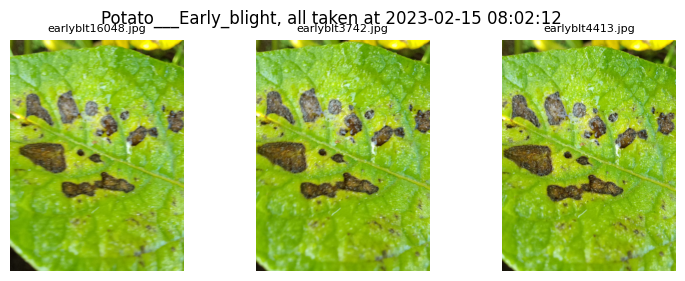

In [7]:
# How many photos share exactly the same capture second?
timed = inventory.dropna(subset=["capture_time"])
same_second = timed.groupby(["class", "capture_time"]).size()
print("Full inventory, photos per identical time stamp:")
display(same_second.groupby("class").describe()[["count", "mean", "50%", "max"]])

sample_times = tz_pool.merge(inventory[["class", "file", "capture_time"]], on=["class", "file"])
in_sample = sample_times.groupby(["class", "capture_time"]).size()
print("Sample, photos per identical time stamp:")
display(in_sample.groupby("class").agg(stamps="size", largest="max", shared=lambda s: (s > 1).sum()))

# Show the sampled early-blight photos that share the most common time stamp.
from PIL import Image
import matplotlib.pyplot as plt

cls = "Potato___Early_blight"
stamp = in_sample.loc[cls].idxmax()
files = sample_times.loc[(sample_times["class"] == cls) & (sample_times["capture_time"] == stamp), "file"].head(6).tolist()
fig, axes = plt.subplots(1, len(files), figsize=(3 * len(files), 3), squeeze=False)
for ax, f in zip(axes[0], files):
    ax.imshow(Image.open(config.TANZANIA_DIR / cls / f))
    ax.set_title(f, fontsize=8)
    ax.axis("off")
plt.suptitle(f"{cls}, all taken at {stamp}")
plt.show()


In [8]:
SECOND_CUTOFFS = [0, 5 / 60, 10 / 60, 20 / 60, 30 / 60]   # 0 s, 5 s, 10 s, 20 s, 30 s (in minutes)
table = split.gap_table(inventory, tz_pool, SECOND_CUTOFFS)
table.insert(1, "cutoff_s", (table.pop("cutoff_min") * 60).round().astype(int))
display(table)


,class,cutoff_s,sessions,median_size,largest_size,largest_in_sample,largest_share_of_sample
0,Potato___Early_blight,0,2774,4,355,3,0.004
1,Potato___Late_blight,0,8397,2,29,3,0.003
2,Potato___healthy,0,16049,1,13,2,0.002
3,Potato___Early_blight,5,682,8,1346,46,0.055
4,Potato___Late_blight,5,2440,5,349,14,0.014
5,Potato___healthy,5,4243,2,96,9,0.009
6,Potato___Early_blight,10,457,10,1393,47,0.056
7,Potato___Late_blight,10,1353,7,361,14,0.014
8,Potato___healthy,10,1767,6,304,13,0.013
9,Potato___Early_blight,20,242,16,2596,76,0.091


## Choose the session cut-off

Set `SESSION_GAP_MINUTES` after reading the tables above. If one class has a session too
large to balance, put a smaller cut-off for that class in `SESSION_GAP_OVERRIDES`,
e.g. `{"Potato___Early_blight": 2}`. The table printed here is the session summary for
Chapter 5.

In [9]:
SESSION_GAP_MINUTES = 10 / 60   # 10 seconds
SESSION_GAP_OVERRIDES = {"Potato___Early_blight": 0}   # identical time stamp only

assert SESSION_GAP_MINUTES is not None, "Choose SESSION_GAP_MINUTES from the tables above first."
gap_minutes = {c: SESSION_GAP_OVERRIDES.get(c, SESSION_GAP_MINUTES) for c in config.TANZANIA_CLASS_MAP.values()}

inventory["session"] = split.assign_sessions(inventory, gap_minutes)
tz_pool = tz_pool.merge(inventory[["class", "file", "session"]], on=["class", "file"], how="left")
assert tz_pool["session"].notna().all(), "Some sampled photos were not found in the inventory"

sessions = split.session_summary(tz_pool, gap_minutes)
display(sessions)
sessions.to_csv(config.METADATA_DIR / "tanzania_sessions_summary.csv")

,cutoff_min,images,sessions,median_size,largest_size
class,,,,,
Potato___Early_blight,0.000000,833,704,1.0,3
Potato___Late_blight,0.166667,970,517,1.0,14
Potato___healthy,0.166667,994,577,1.0,13


## Build the groups

Each image collects its grouping keys (leaf, source photo, session, near-duplicate group);
images sharing any key, even through a chain, end up in one group.

In [10]:
leaf_maps_dir = config.PLANTVILLAGE_DIR / "leaf_grouping" / "filtered_leafmaps"
assert leaf_maps_dir.exists(), f"Leaf records missing on Drive: {leaf_maps_dir}"
leaf_of = split.read_leaf_maps(leaf_maps_dir, config.PLANTVILLAGE_CLASSES)

file_name = pool["path"].str.rsplit("/", n=1).str[-1]
is_pv = pool["source"] == "plantvillage"
pool["leaf"] = [
    leaf_of.get((c, split.leaf_name(f))) if pv else None
    for c, f, pv in zip(pool["class"], file_name, is_pv)
]

crops = pd.read_csv(config.METADATA_DIR / "fieldplant_crops.csv")
pool["source_image"] = file_name.map(crops.set_index("crop")["source_image"]).where(pool["source"] == "fieldplant")
assert pool.loc[pool["source"] == "fieldplant", "source_image"].notna().all(), "FieldPlant crops without a source photo"

pool["session"] = pool["path"].map(tz_pool.set_index("path")["session"])
pool["group"] = split.connect(split.group_keys(pool))

print("PlantVillage images with a leaf record:", pool["leaf"].notna().sum(), "of", is_pv.sum())
display(pool[is_pv].assign(has_leaf=pool["leaf"].notna()).groupby("class")["has_leaf"].agg(["sum", "size"]))

group_sizes = pool.groupby("group").size()
print("Groups:", len(group_sizes), "| median size:", int(group_sizes.median()), "| largest:", group_sizes.max())
display(pool.groupby("source")["group"].nunique().rename("groups"))

PlantVillage images with a leaf record: 7197 of 12617


,sum,size
class,,
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0,513
Corn_(maize)___Common_rust_,0,1192
Corn_(maize)___Northern_Leaf_Blight,0,985
Corn_(maize)___healthy,0,1162
Potato___Early_blight,1000,1000
Potato___Late_blight,1000,1000
Potato___healthy,152,152
Tomato___Bacterial_spot,2127,2127
Tomato___Early_blight,999,1000


Groups: 9454 | median size: 1 | largest: 14


,groups
source,
fieldplant,507
plantvillage,7201
tanzania,1746


## Split

In [11]:
ratios = (config.TRAIN_RATIO, config.VAL_RATIO, config.TEST_RATIO)
pool["partition"] = split.assign_partitions(pool, config.SPLIT_FOLDS, ratios, config.RANDOM_SEED)

display(pool["partition"].value_counts().reindex(split.PARTITIONS).rename("images"))
display((split.shares(pool, "class") * 100).round(1))
display((split.shares(pool, "source") * 100).round(1))

,images
partition,
train,11477
val,2385
test,2441


partition,train,val,test
class,,,
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,69.7,13.9,16.4
Corn_(maize)___Common_rust_,70.3,14.9,14.8
Corn_(maize)___Northern_Leaf_Blight,69.6,15.1,15.2
Corn_(maize)___healthy,69.4,15.3,15.3
Potato___Early_blight,70.0,14.7,15.2
Potato___Late_blight,71.3,13.7,15.1
Potato___healthy,70.5,14.7,14.7
Tomato___Bacterial_spot,71.4,14.3,14.3
Tomato___Early_blight,68.0,16.0,16.0


partition,train,val,test
source,,,
fieldplant,69.5,14.1,16.4
plantvillage,70.2,14.9,14.9
tanzania,71.4,13.7,14.9


## Checks

Each check stops the notebook with an error if it fails.

In [12]:
for line in split.check(pool, set(ood_test["path"]) | set(unseen_test["path"]), ratios, config.SPLIT_TOLERANCE):
    print("PASS:", line)

PASS: Every one of 9454 groups sits in a single partition
PASS: No PlantDoc image is in train, val or test
PASS: No image appears twice
PASS: Every class appears in train, val and test
PASS: Every class's share of each partition is within 3% of target (worst 2.0%)
PASS: Every source's share of each partition is within 3% of target (worst 1.4%)


## Save the split

`train.csv`, `val.csv`, `test.csv`, `ood_test.csv` (PlantDoc, in-scope classes) and
`unseen_test.csv` (PlantDoc, unseen tomato diseases) go to `datasets/splits/`, with paths
relative to the raw data folder. `split_summary.csv` has images per source, class and
partition, for per-source reporting in Chapter 5.

In [13]:
config.SPLITS_DIR.mkdir(parents=True, exist_ok=True)
columns = ["path", "class", "source", "group"]

for name in split.PARTITIONS:
    pool.loc[pool["partition"] == name, columns].to_csv(config.SPLITS_DIR / f"{name}.csv", index=False)
ood_test.assign(group=pd.NA)[columns].to_csv(config.SPLITS_DIR / "ood_test.csv", index=False)
unseen_test.assign(group=pd.NA)[columns].to_csv(config.SPLITS_DIR / "unseen_test.csv", index=False)

summary = split.summary_table(pool)
summary.to_csv(config.SPLITS_DIR / "split_summary.csv", index=False)
display(summary)
print("Saved to", config.SPLITS_DIR, ":", sorted(p.name for p in config.SPLITS_DIR.iterdir()))

partition,source,class,train,val,test,total,train_share,val_share,test_share
0,fieldplant,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,33,4,17,54,0.611,0.074,0.315
1,fieldplant,Corn_(maize)___healthy,97,27,28,152,0.638,0.178,0.184
2,fieldplant,Tomato___Late_blight,276,70,58,404,0.683,0.173,0.144
3,fieldplant,Tomato___healthy,212,24,43,279,0.760,0.086,0.154
4,plantvillage,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,362,75,76,513,0.706,0.146,0.148
5,plantvillage,Corn_(maize)___Common_rust_,838,178,176,1192,0.703,0.149,0.148
6,plantvillage,Corn_(maize)___Northern_Leaf_Blight,686,149,150,985,0.696,0.151,0.152
7,plantvillage,Corn_(maize)___healthy,815,174,173,1162,0.701,0.150,0.149
8,plantvillage,Potato___Early_blight,688,156,156,1000,0.688,0.156,0.156
9,plantvillage,Potato___Late_blight,704,152,144,1000,0.704,0.152,0.144


Saved to /content/drive/MyDrive/CropDiseaseDiagnosis/datasets/splits : ['ood_test.csv', 'split_summary.csv', 'test.csv', 'train.csv', 'unseen_test.csv', 'val.csv']


## Make sure Drive has saved everything

Colab uploads files to Drive in the background; this waits until the upload has finished
(see DEF-01), then reconnects Drive for the push.

In [14]:
drive.flush_and_unmount()
drive.mount("/content/drive")
print("Drive synced and remounted.")

Mounted at /content/drive
Drive synced and remounted.


## Save to GitHub

Commits the changed notebook to a new branch and prints a link to open the pull
request (`main` is protected). Change the branch name if this cell has already been
run once. Save the notebook (Ctrl+S) before running this cell.

In [ ]:
from google.colab import userdata

from src import github_sync

print(github_sync.status(REPO_DIR))
print()
print(github_sync.push(
    REPO_DIR,
    branch="colab/data-split",
    message="Split the training pool into grouped, stratified train, val and test",
    token=userdata.get("GITHUB_TOKEN"),
    name="BilliartMuthoni",
    email=userdata.get("GIT_EMAIL"),
))